In [880]:
import pandas as pd
import os
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split 

In [881]:
base_dir = Path(os.getcwd()).parent
file_path = base_dir / 'data' / 'wfp_market_food_prices.csv'
df = pd.read_csv(file_path, encoding='latin1')

In [882]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 743914 entries, 0 to 743913
Data columns (total 18 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   adm0_id             743914 non-null  int64  
 1   adm0_name           743914 non-null  str    
 2   adm1_id             743914 non-null  int64  
 3   adm1_name           729965 non-null  str    
 4   mkt_id              743914 non-null  int64  
 5   mkt_name            743914 non-null  str    
 6   cm_id               743914 non-null  int64  
 7   cm_name             743914 non-null  str    
 8   cur_id              743914 non-null  int64  
 9   cur_name            743914 non-null  str    
 10  pt_id               743914 non-null  int64  
 11  pt_name             743914 non-null  str    
 12  um_id               743914 non-null  int64  
 13  um_name             743914 non-null  str    
 14  mp_month            743914 non-null  int64  
 15  mp_year             743914 non-null  int64  


In [883]:
df.dtypes

adm0_id                 int64
adm0_name                 str
adm1_id                 int64
adm1_name                 str
mkt_id                  int64
mkt_name                  str
cm_id                   int64
cm_name                   str
cur_id                  int64
cur_name                  str
pt_id                   int64
pt_name                   str
um_id                   int64
um_name                   str
mp_month                int64
mp_year                 int64
mp_price              float64
mp_commoditysource        str
dtype: object

In [884]:
df.duplicated().sum()

np.int64(0)

In [885]:
df.isna().sum()

adm0_id                   0
adm0_name                 0
adm1_id                   0
adm1_name             13949
mkt_id                    0
mkt_name                  0
cm_id                     0
cm_name                   0
cur_id                    0
cur_name                  0
pt_id                     0
pt_name                   0
um_id                     0
um_name                   0
mp_month                  0
mp_year                   0
mp_price                  0
mp_commoditysource        0
dtype: int64

In [886]:
df.isna().sum()

adm0_id                   0
adm0_name                 0
adm1_id                   0
adm1_name             13949
mkt_id                    0
mkt_name                  0
cm_id                     0
cm_name                   0
cur_id                    0
cur_name                  0
pt_id                     0
pt_name                   0
um_id                     0
um_name                   0
mp_month                  0
mp_year                   0
mp_price                  0
mp_commoditysource        0
dtype: int64

In [887]:
df["adm1_name"].value_counts()

adm1_name
$North/Amajyaruguru             28850
$West/Iburengerazuba            27831
$South/Amajyepfo                24325
$East/Iburasirazuba             23144
Kigali City/Umujyi wa Kigali    10887
                                ...  
Preah Vihear                       11
South Kordofan                      7
Northern Darfur                     5
West Darfur                         5
West Kordofan                       5
Name: count, Length: 588, dtype: int64

In [888]:
df.fillna({"adm1_name":"Unknown"},inplace=True)

,adm0_id,adm0_name,adm1_id,adm1_name,mkt_id,mkt_name,cm_id,cm_name,cur_id,cur_name,pt_id,pt_name,um_id,um_name,mp_month,mp_year,mp_price,mp_commoditysource
0,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,1,2014,50.0,WFP
1,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,2,2014,50.0,WFP
2,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,3,2014,50.0,WFP
3,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,4,2014,50.0,WFP
4,1,Afghanistan,272,Badakhshan,266,Fayzabad,55,Bread,87,AFN,15,Retail,5,KG,5,2014,50.0,WFP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
743909,70001,South Sudan,2750,Eastern Equatoria,1786,Torit,156,Sesame,83,SSP,15,Retail,47,3.5 KG,5,2017,400.0,WFP
743910,70001,South Sudan,2750,Eastern Equatoria,1786,Torit,284,Fuel (diesel),83,SSP,15,Retail,15,L,2,2017,12.5,WFP
743911,70001,South Sudan,2750,Eastern Equatoria,1786,Torit,284,Fuel (diesel),83,SSP,15,Retail,15,L,3,2017,95.0,WFP
743912,70001,South Sudan,2750,Eastern Equatoria,1786,Torit,285,Fuel (petrol-gasoline),83,SSP,15,Retail,15,L,2,2017,95.0,WFP


In [889]:
df.isna().sum()

adm0_id               0
adm0_name             0
adm1_id               0
adm1_name             0
mkt_id                0
mkt_name              0
cm_id                 0
cm_name               0
cur_id                0
cur_name              0
pt_id                 0
pt_name               0
um_id                 0
um_name               0
mp_month              0
mp_year               0
mp_price              0
mp_commoditysource    0
dtype: int64

In [890]:
df["adm1_name"].value_counts()

adm1_name
$North/Amajyaruguru     28850
$West/Iburengerazuba    27831
$South/Amajyepfo        24325
$East/Iburasirazuba     23144
Unknown                 13949
                        ...  
Preah Vihear               11
South Kordofan              7
Northern Darfur             5
West Darfur                 5
West Kordofan               5
Name: count, Length: 589, dtype: int64

In [891]:
print((df['adm0_name'] == 'India').sum())

68308


In [892]:
df = df[df["adm0_name"].isin(["India"])]

In [893]:
print(df["adm0_name"].unique())

<ArrowStringArray>
['India']
Length: 1, dtype: str


In [894]:
df.drop(columns=['adm0_id','adm1_id','mkt_id','cm_id','cur_id','pt_id',"um_id"],inplace=True)

In [895]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 68308 entries, 155658 to 223965
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   adm0_name           68308 non-null  str    
 1   adm1_name           68308 non-null  str    
 2   mkt_name            68308 non-null  str    
 3   cm_name             68308 non-null  str    
 4   cur_name            68308 non-null  str    
 5   pt_name             68308 non-null  str    
 6   um_name             68308 non-null  str    
 7   mp_month            68308 non-null  int64  
 8   mp_year             68308 non-null  int64  
 9   mp_price            68308 non-null  float64
 10  mp_commoditysource  68308 non-null  str    
dtypes: float64(1), int64(2), str(8)
memory usage: 13.2 MB


In [896]:
cat_features = ["adm0_name","adm1_name","mkt_name","cur_name","pt_name","um_name","cm_name","mp_commoditysource"]
num_features = ["mp_month","mp_year","mp_price"]

In [897]:
df.describe()

,mp_month,mp_year,mp_price
count,68308.000000,68308.000000,68308.000000
mean,6.391916,2012.808968,53.909238
std,3.418735,4.802383,47.875561
min,1.000000,1994.000000,3.800000
25%,4.000000,2012.000000,19.000000
50%,6.000000,2014.000000,35.000000
75%,9.000000,2016.000000,79.000000
max,12.000000,2017.000000,400.000000


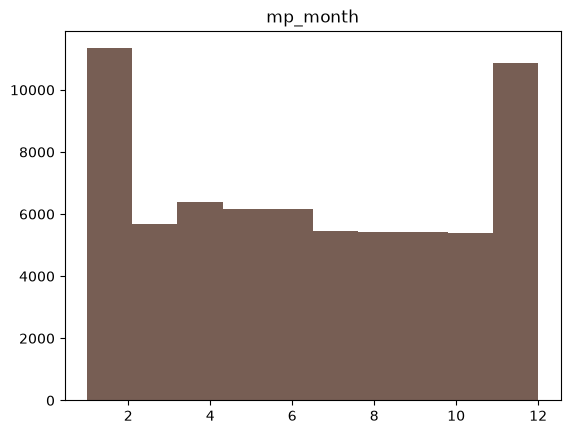

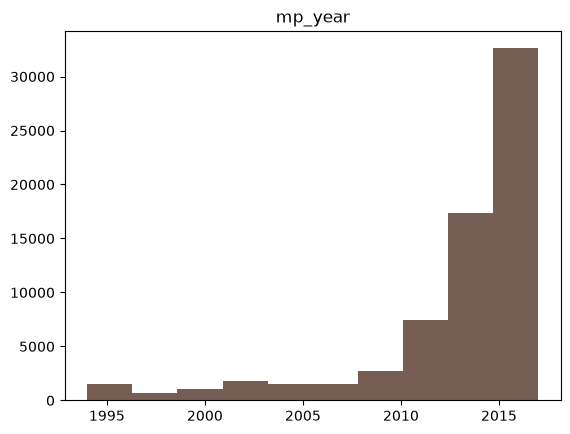

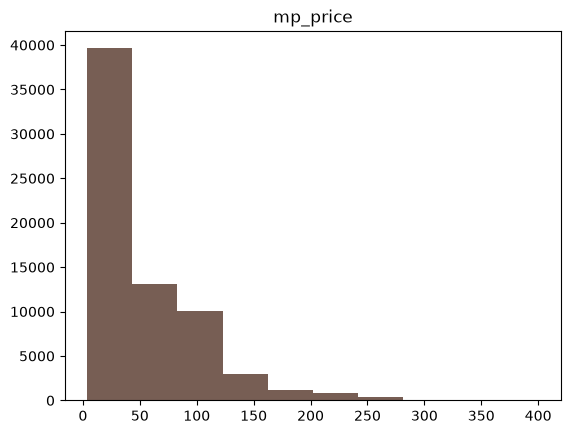

In [898]:
for i in num_features :
    plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#775E54"])
    plt.hist(df[i])
    plt.title(f"{i}")
    plt.show()

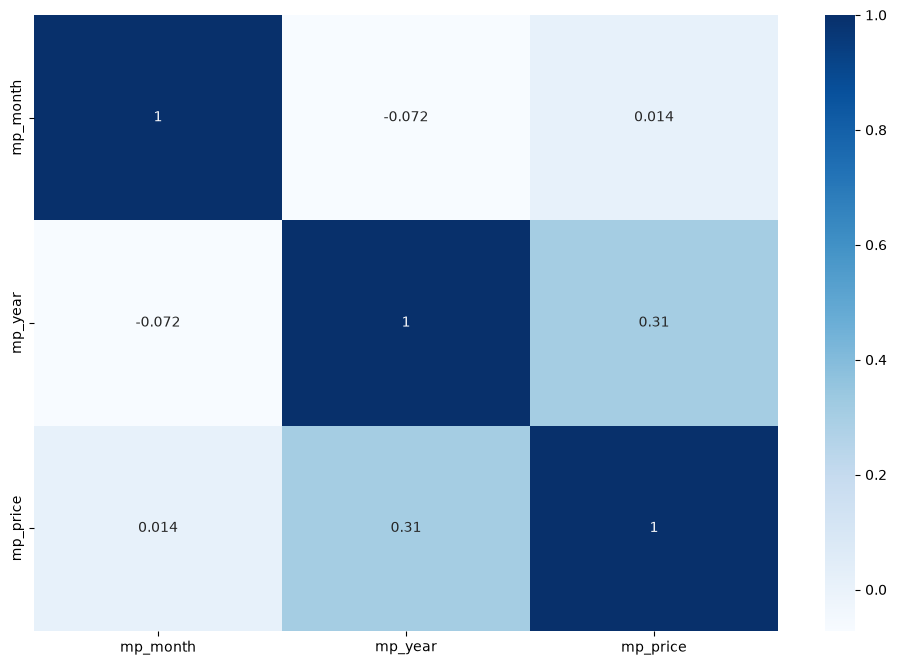

In [899]:
plt.figure(figsize=(12,8))
sns.heatmap(
    df[num_features].corr(),
    annot = True ,
    cmap = "Blues",
    )
plt.show()

In [900]:
df.drop(columns=["mp_month"],inplace=True)

In [901]:
x = df.drop("mp_price", axis= 1)
y = df['mp_price']

x_train , x_test ,y_train ,y_test = train_test_split(x, y, test_size=0.15, random_state=42)
x_train , x_validation ,y_train ,y_validation = train_test_split(x_train, y_train, test_size=0.15, random_state=42)

In [902]:
x_train = x_train.reset_index(drop=True)
x_test = x_test.reset_index(drop=True)
x_validation = x_validation.reset_index(drop=True)

In [903]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

encoded_train = pd.DataFrame(
    encoder.fit_transform(x_train[cat_features]), 
    columns=encoder.get_feature_names_out(cat_features)
)
x_train = pd.concat([x_train.drop(columns=cat_features), encoded_train], axis=1)

encoded_test = pd.DataFrame(
    encoder.transform(x_test[cat_features]),
    columns=encoder.get_feature_names_out(cat_features)
)
x_test = pd.concat([x_test.drop(columns=cat_features),encoded_test],axis=1)

encoded_validation = pd.DataFrame(
    encoder.transform(x_validation[cat_features]),
    columns=encoder.get_feature_names_out(cat_features)
)
x_validation = pd.concat([x_validation.drop(columns=cat_features),encoded_validation],axis=1)

In [904]:
x_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 49351 entries, 0 to 49350
Columns: 118 entries, mp_year to mp_commoditysource_M/o Consumer Affairs, Food and Public Distribution, Government of India
dtypes: float64(117), int64(1)
memory usage: 44.4 MB


In [905]:
x_train.isna().sum()

mp_year                                                                                       0
adm0_name_India                                                                               0
adm1_name_$Chandigarh                                                                         0
adm1_name_$Jharkhand                                                                          0
adm1_name_$Puducherry                                                                         0
                                                                                             ..
cm_name_Tea (black)                                                                           0
cm_name_Tomatoes                                                                              0
cm_name_Wheat                                                                                 0
cm_name_Wheat flour                                                                           0
mp_commoditysource_M/o Consumer Affairs,

In [906]:
x_train.dtypes

mp_year                                                                                         int64
adm0_name_India                                                                               float64
adm1_name_$Chandigarh                                                                         float64
adm1_name_$Jharkhand                                                                          float64
adm1_name_$Puducherry                                                                         float64
                                                                                               ...   
cm_name_Tea (black)                                                                           float64
cm_name_Tomatoes                                                                              float64
cm_name_Wheat                                                                                 float64
cm_name_Wheat flour                                                               

In [907]:
num_features = ["mp_year"]

In [908]:
scaler = RobustScaler()
x_train[num_features] = scaler.fit_transform(x_train[num_features])
x_validation[num_features] = scaler.transform(x_validation[num_features])
x_test[num_features] = scaler.transform(x_test[num_features])